In [2]:
import os
import sys
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from tqdm import tqdm
try:
    from IPython.display import display
except ImportError:
    display = print

# Set plot styling
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
sns.set_theme(style="whitegrid", palette="muted")

# Set random seed for reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Environment initialized successfully.")
print(f"NumPy:  {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"OpenCV: {cv2.__version__}")

Environment initialized successfully.
NumPy:  2.5.2
Pandas: 2.3.3
OpenCV: 5.0.0


In [3]:
# Determine project root robustly
CURRENT_DIR = Path(".").resolve()
if (CURRENT_DIR / "dataset" / "LSUI").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "dataset" / "LSUI").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError("Could not locate dataset/LSUI. Please check directory structure.")

DATASET_DIR = PROJECT_ROOT / "dataset" / "LSUI"
INPUT_DIR = DATASET_DIR / "input"
GT_DIR = DATASET_DIR / "GT"

print(f"Project root:  {PROJECT_ROOT}")
print(f"Input path:    {INPUT_DIR} (Exists: {INPUT_DIR.exists()})")
print(f"GT path:       {GT_DIR} (Exists: {GT_DIR.exists()})")

Project root:  E:\sem5_project
Input path:    E:\sem5_project\dataset\LSUI\input (Exists: True)
GT path:       E:\sem5_project\dataset\LSUI\GT (Exists: True)


In [4]:
# Sort files numerically based on stem (0.jpg, 1.jpg, ...)
sort_key = lambda p: int(p.stem) if p.stem.isdigit() else p.stem
input_files = sorted(list(INPUT_DIR.glob("*.jpg")), key=sort_key)
gt_files = sorted(list(GT_DIR.glob("*.jpg")), key=sort_key)

input_names = {p.name for p in input_files}
gt_names = {p.name for p in gt_files}

common_pairs = input_names.intersection(gt_names)
missing_in_gt = input_names - gt_names
missing_in_input = gt_names - input_names

print(f"Total raw input images:        {len(input_files):,}")
print(f"Total ground-truth (GT) images:{len(gt_files):,}")
print(f"Matching image pairs:          {len(common_pairs):,}")
print(f"Missing in GT:                 {len(missing_in_gt)}")
print(f"Missing in Input:              {len(missing_in_input)}")

assert len(common_pairs) == len(input_files) == len(gt_files), "Pairing mismatch detected!"
print("\n[SUCCESS] Dataset integrity verified: 100% 1-to-1 pairing!")

Total raw input images:        4,279
Total ground-truth (GT) images:4,279
Matching image pairs:          4,279
Missing in GT:                 0
Missing in Input:              0

[SUCCESS] Dataset integrity verified: 100% 1-to-1 pairing!


In [5]:
metadata_records = []

print("Profiling all 4,279 image pairs...")
for img_path in tqdm(input_files, desc="Scanning Metadata"):
    gt_path = GT_DIR / img_path.name
    
    in_size_kb = img_path.stat().st_size / 1024.0
    gt_size_kb = gt_path.stat().st_size / 1024.0
    
    # Fast header reading with PIL without decoding full image array
    with Image.open(img_path) as im:
        width, height = im.size
        mode = im.mode
        
    aspect_ratio = round(width / height, 3)
    megapixels = round((width * height) / 1e6, 3)
    
    metadata_records.append({
        "id": img_path.stem,
        "filename": img_path.name,
        "width": width,
        "height": height,
        "aspect_ratio": aspect_ratio,
        "megapixels": megapixels,
        "input_size_kb": round(in_size_kb, 2),
        "gt_size_kb": round(gt_size_kb, 2),
        "mode": mode
    })

df_meta = pd.DataFrame(metadata_records)
print(f"Metadata extraction complete: {len(df_meta)} records.")
df_meta.head()

Profiling all 4,279 image pairs...


Scanning Metadata: 100%|██████████| 4279/4279 [00:00<00:00, 6085.61it/s]


Metadata extraction complete: 4279 records.


,id,filename,width,height,aspect_ratio,megapixels,input_size_kb,gt_size_kb,mode
0,0,0.jpg,640,320,2.000,0.205,18.79,34.22,RGB
1,1,1.jpg,720,405,1.778,0.292,40.42,64.59,RGB
2,2,2.jpg,720,405,1.778,0.292,34.15,55.78,RGB
3,3,3.jpg,640,360,1.778,0.230,72.33,88.17,RGB
4,4,4.jpg,640,360,1.778,0.230,73.77,92.69,RGB


In [6]:
summary_cols = ["width", "height", "aspect_ratio", "megapixels", "input_size_kb", "gt_size_kb"]
df_meta[summary_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
width,4279.0,447.036691,211.202480,256.000,320.000,320.000,640.000,1280.000
height,4279.0,309.165693,128.863975,225.000,240.000,256.000,360.000,1024.000
aspect_ratio,4279.0,1.417330,0.251244,1.000,1.333,1.333,1.778,2.000
megapixels,4279.0,0.163084,0.204550,0.066,0.077,0.077,0.230,1.311
input_size_kb,4279.0,49.474945,82.768401,5.960,22.220,27.340,50.600,690.810
gt_size_kb,4279.0,65.144676,89.596287,10.350,34.650,43.670,66.030,721.080


C:\Users\GYANENDRA\AppData\Local\Temp\ipykernel_5024\3229411585.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_aspects.index.astype(str), y=top_aspects.values, palette="Blues_d", ax=axes[1, 0])


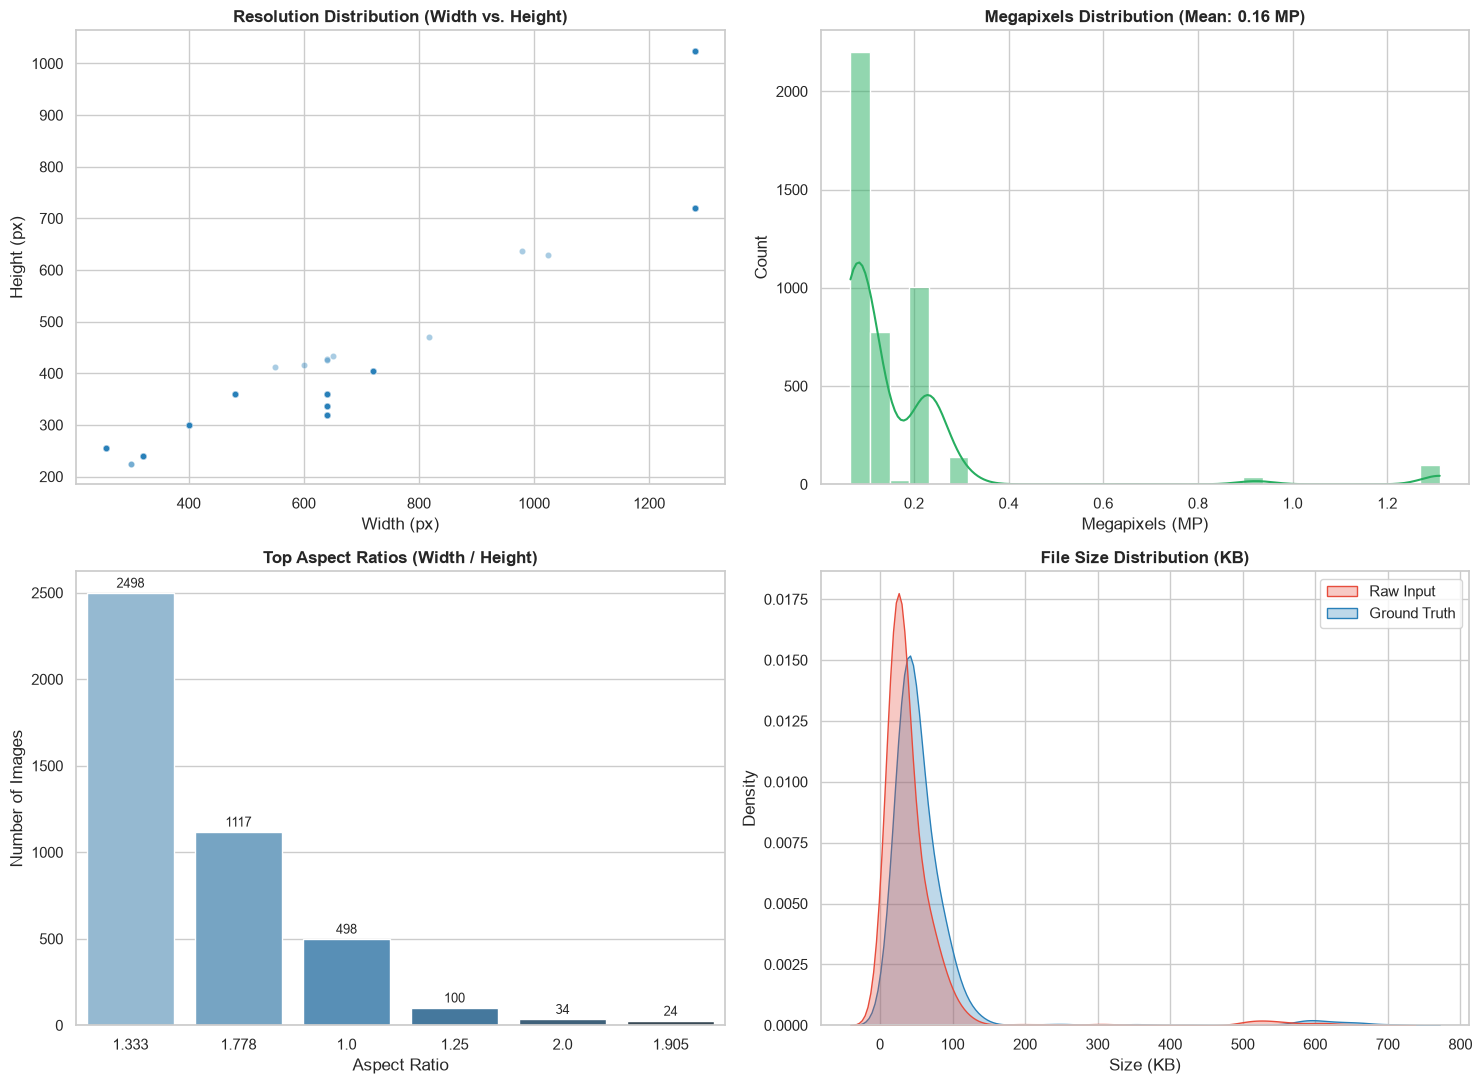

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Width vs Height Scatter Plot
sns.scatterplot(data=df_meta, x="width", y="height", alpha=0.4, s=20, color="#2980b9", ax=axes[0, 0])
axes[0, 0].set_title("Resolution Distribution (Width vs. Height)", fontweight="bold")
axes[0, 0].set_xlabel("Width (px)")
axes[0, 0].set_ylabel("Height (px)")

# 2. Megapixels Distribution
sns.histplot(df_meta["megapixels"], bins=30, kde=True, color="#27ae60", ax=axes[0, 1])
axes[0, 1].set_title(f"Megapixels Distribution (Mean: {df_meta['megapixels'].mean():.2f} MP)", fontweight="bold")
axes[0, 1].set_xlabel("Megapixels (MP)")

# 3. Most Common Aspect Ratios
top_aspects = df_meta["aspect_ratio"].value_counts().head(6)
sns.barplot(x=top_aspects.index.astype(str), y=top_aspects.values, palette="Blues_d", ax=axes[1, 0])
axes[1, 0].set_title("Top Aspect Ratios (Width / Height)", fontweight="bold")
axes[1, 0].set_xlabel("Aspect Ratio")
axes[1, 0].set_ylabel("Number of Images")
for p in axes[1, 0].patches:
    axes[1, 0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

# 4. File Size Comparison: Input vs GT
size_data = pd.DataFrame({
    "Raw Input": df_meta["input_size_kb"],
    "Ground Truth": df_meta["gt_size_kb"]
})
sns.kdeplot(data=size_data, fill=True, common_norm=False, palette=["#e74c3c", "#2980b9"], alpha=0.3, ax=axes[1, 1])
axes[1, 1].set_title("File Size Distribution (KB)", fontweight="bold")
axes[1, 1].set_xlabel("Size (KB)")

plt.tight_layout()
plt.show()

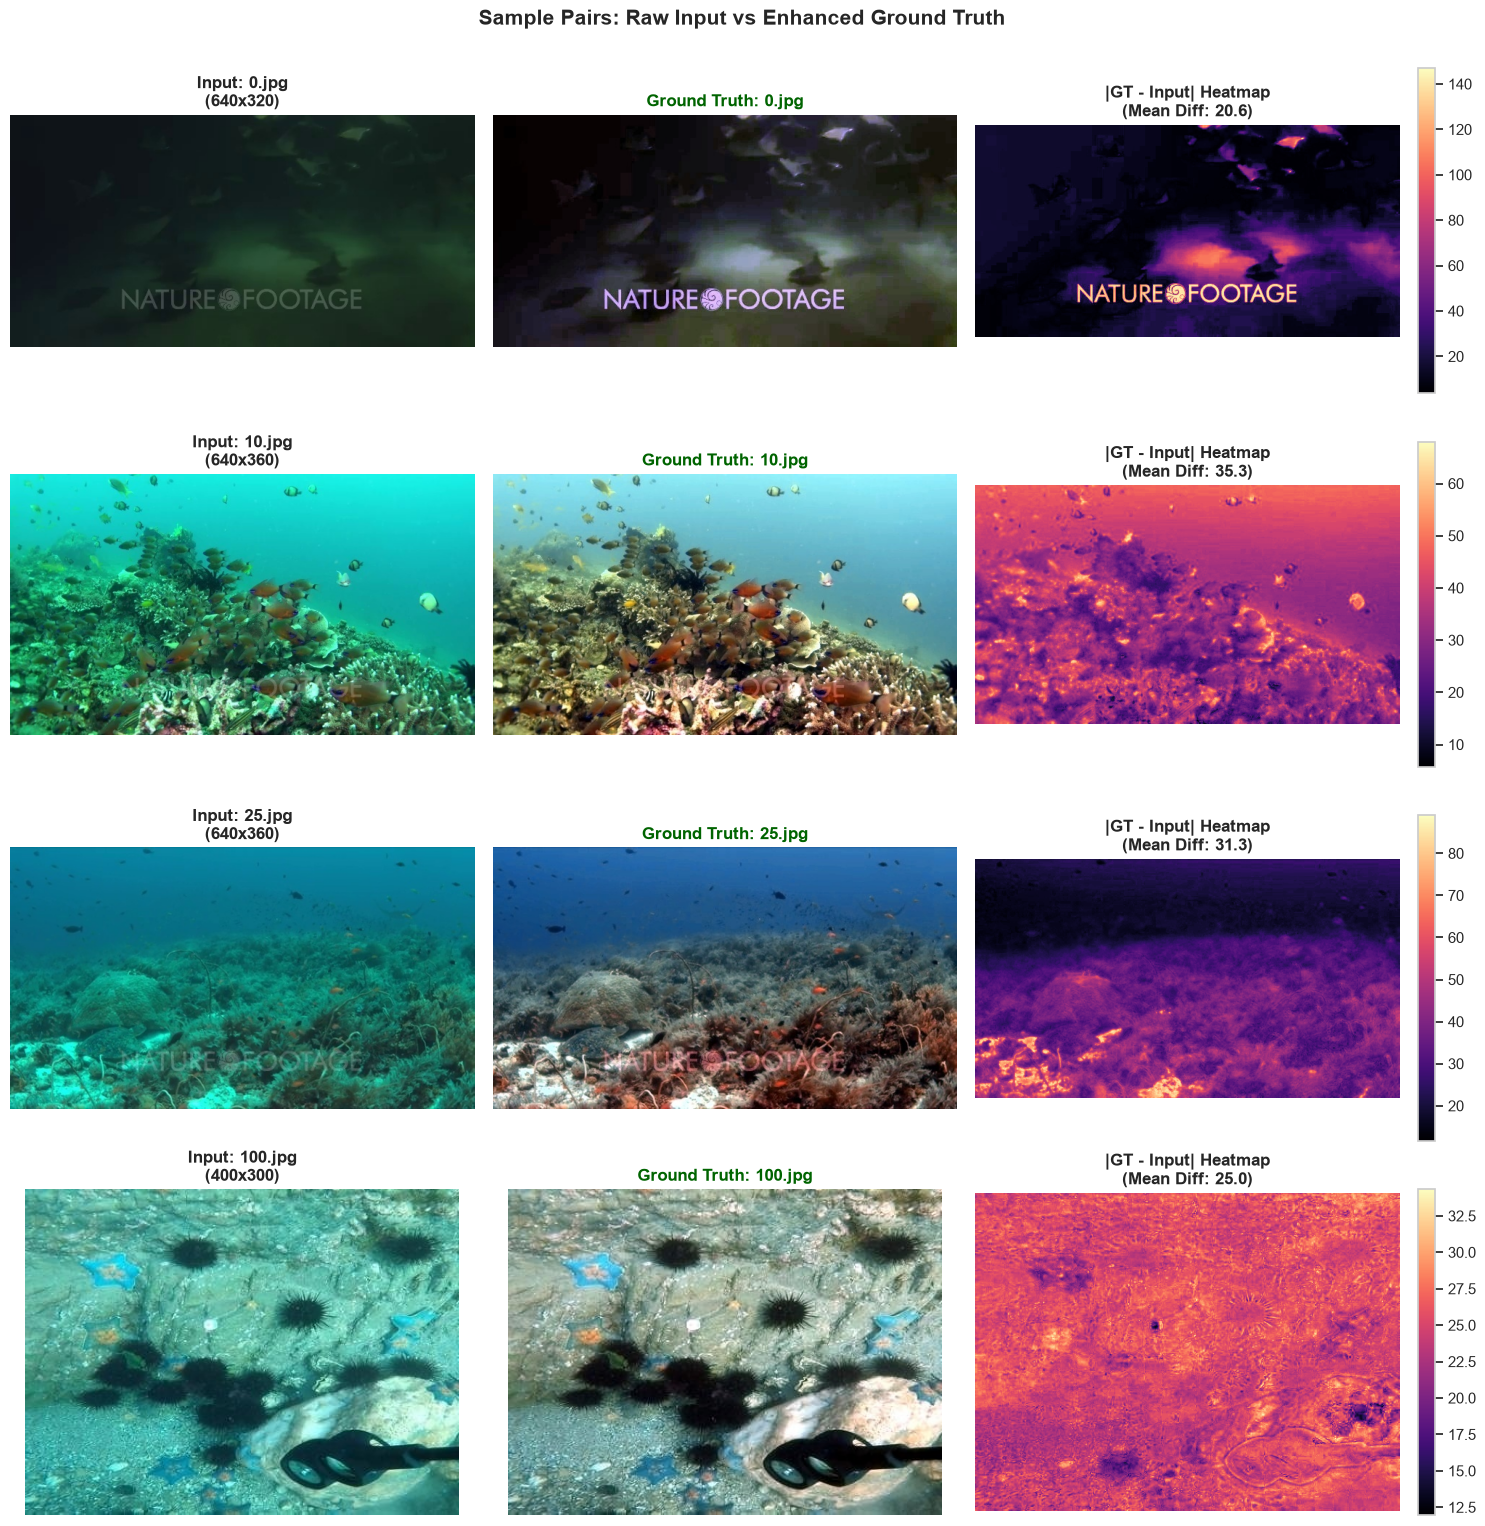

In [8]:
def load_image_pair(image_id_or_name):
    """Loads input and GT images as RGB arrays."""
    name = f"{image_id_or_name}.jpg" if not str(image_id_or_name).endswith(".jpg") else str(image_id_or_name)
    in_path = INPUT_DIR / name
    gt_path = GT_DIR / name
    
    img_in = cv2.cvtColor(cv2.imread(str(in_path)), cv2.COLOR_BGR2RGB)
    img_gt = cv2.cvtColor(cv2.imread(str(gt_path)), cv2.COLOR_BGR2RGB)
    return img_in, img_gt, name

def plot_image_pairs(sample_names, title="LSUI Input vs Ground-Truth Comparison"):
    """Displays paired images alongside absolute difference heatmaps."""
    n = len(sample_names)
    fig, axes = plt.subplots(n, 3, figsize=(15, 3.8 * n))
    if n == 1:
        axes = np.expand_dims(axes, 0)
        
    for idx, name in enumerate(sample_names):
        img_in, img_gt, _ = load_image_pair(name)
        diff = cv2.absdiff(img_gt, img_in)
        diff_intensity = np.mean(diff, axis=-1)
        
        # Input
        axes[idx, 0].imshow(img_in)
        axes[idx, 0].set_title(f"Input: {name}\n({img_in.shape[1]}x{img_in.shape[0]})", fontweight="bold")
        axes[idx, 0].axis("off")
        
        # Ground Truth
        axes[idx, 1].imshow(img_gt)
        axes[idx, 1].set_title(f"Ground Truth: {name}", fontweight="bold", color="darkgreen")
        axes[idx, 1].axis("off")
        
        # Difference Heatmap
        im = axes[idx, 2].imshow(diff_intensity, cmap="magma")
        axes[idx, 2].set_title(f"|GT - Input| Heatmap\n(Mean Diff: {diff_intensity.mean():.1f})", fontweight="bold")
        axes[idx, 2].axis("off")
        plt.colorbar(im, ax=axes[idx, 2], fraction=0.046, pad=0.04)
        
    plt.suptitle(title, fontsize=15, y=1.002, fontweight="bold")
    plt.tight_layout()
    plt.show()

# Visualize sample pairs
sample_selection = ["0.jpg", "10.jpg", "25.jpg", "100.jpg"]
plot_image_pairs(sample_selection, title="Sample Pairs: Raw Input vs Enhanced Ground Truth")

Identified Archetypes:
- Severe Green Cast:   732.jpg
- Dominant Blue Cast:  3421.jpg
- Low Illumination:    4159.jpg
- High Haze / Turbid:  1905.jpg


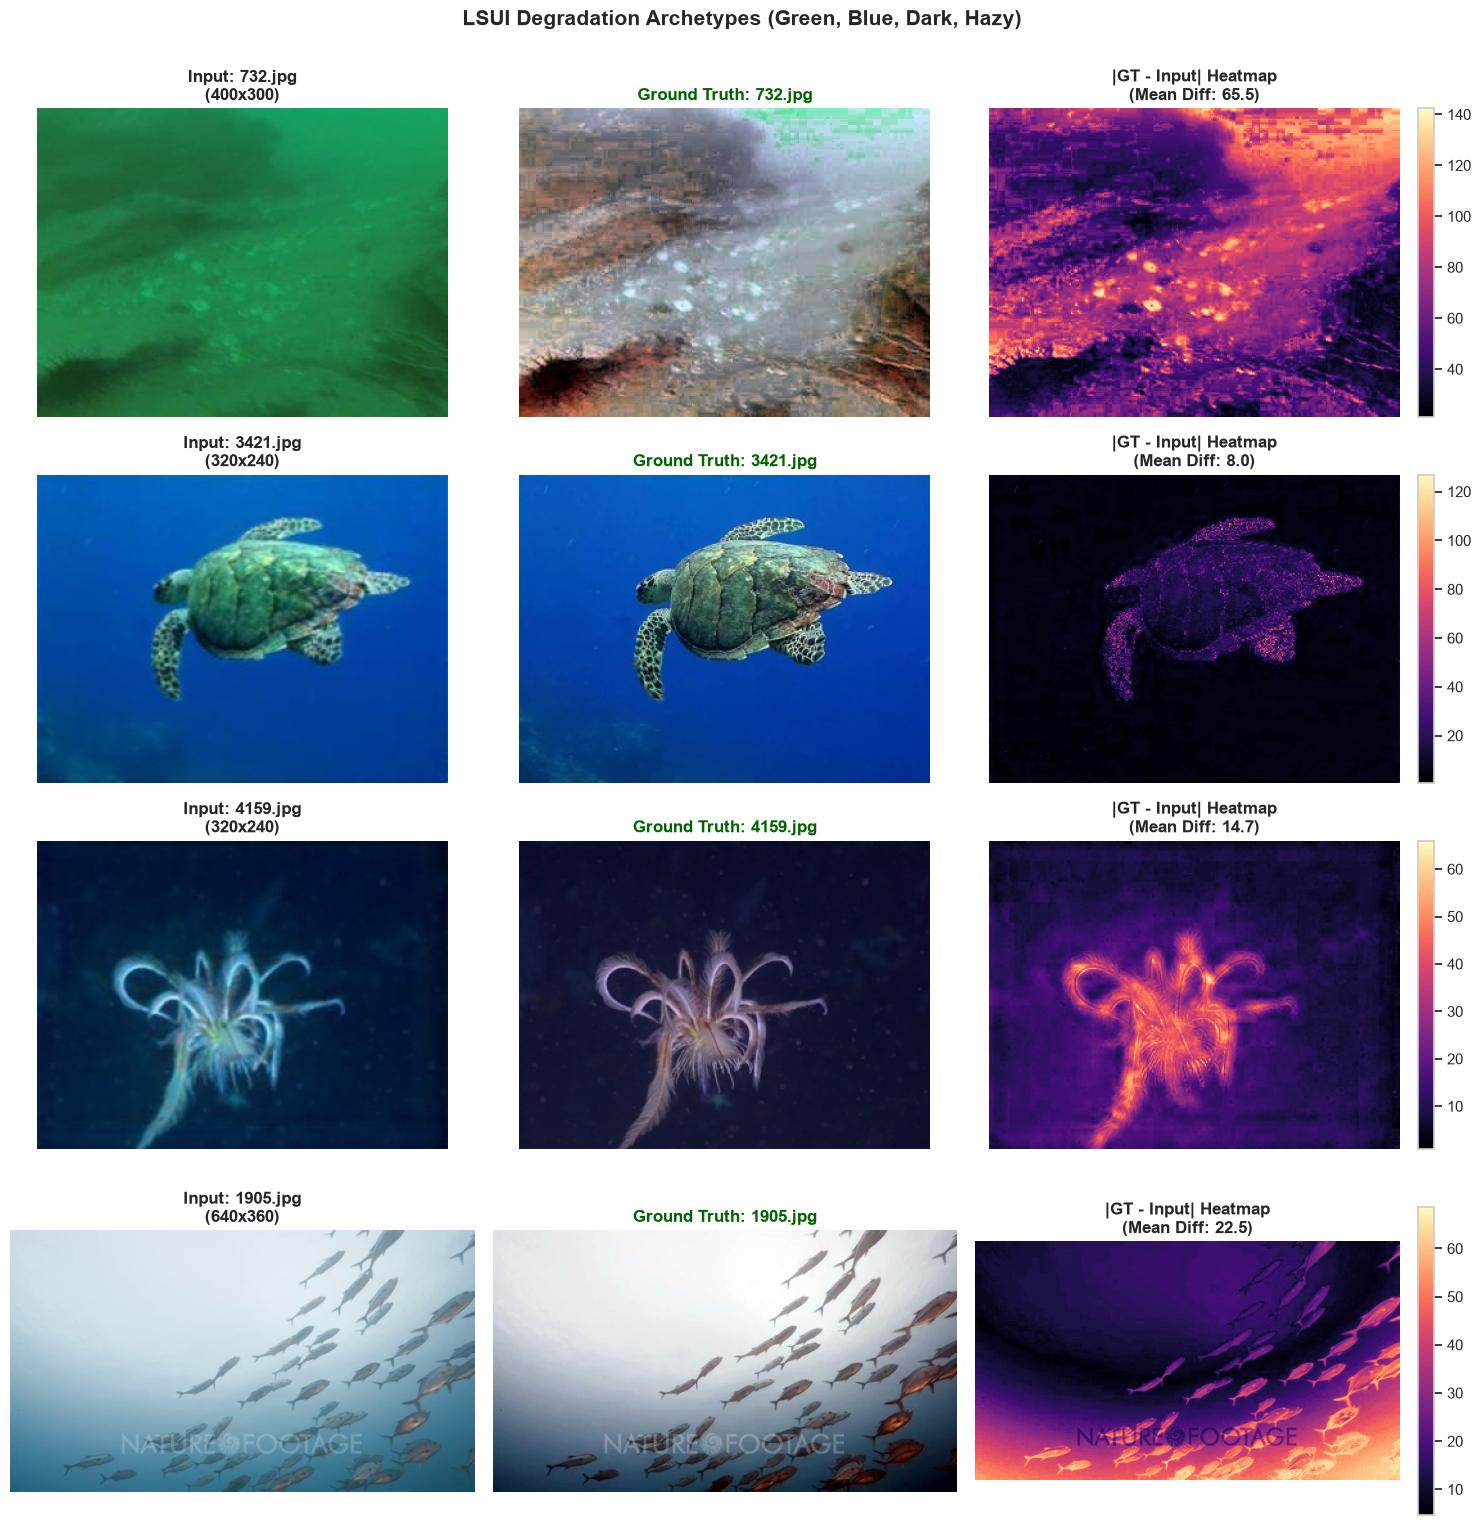

In [9]:
def compute_color_bias(img_rgb):
    r_mean = float(np.mean(img_rgb[:, :, 0]))
    g_mean = float(np.mean(img_rgb[:, :, 1]))
    b_mean = float(np.mean(img_rgb[:, :, 2]))
    
    brightness = (r_mean + g_mean + b_mean) / 3.0
    g_bias = g_mean / (r_mean + b_mean + 1e-5)
    b_bias = b_mean / (r_mean + g_mean + 1e-5)
    
    return {
        "r_mean": r_mean, "g_mean": g_mean, "b_mean": b_mean,
        "brightness": brightness, "g_bias": g_bias, "b_bias": b_bias
    }

# Evaluate color biases on a subset of 500 images
sample_subset = df_meta.sample(n=min(500, len(df_meta)), random_state=RANDOM_SEED)
bias_records = []

for _, row in sample_subset.iterrows():
    img_in, _, _ = load_image_pair(row["filename"])
    m = compute_color_bias(img_in)
    m["filename"] = row["filename"]
    bias_records.append(m)

df_bias = pd.DataFrame(bias_records)

# Identify extreme archetypes
green_archetype = df_bias.sort_values("g_bias", ascending=False).iloc[0]["filename"]
blue_archetype = df_bias.sort_values("b_bias", ascending=False).iloc[0]["filename"]
dark_archetype = df_bias.sort_values("brightness", ascending=True).iloc[0]["filename"]
bright_archetype = df_bias.sort_values("brightness", ascending=False).iloc[0]["filename"]

archetype_files = [green_archetype, blue_archetype, dark_archetype, bright_archetype]
print("Identified Archetypes:")
print(f"- Severe Green Cast:   {green_archetype}")
print(f"- Dominant Blue Cast:  {blue_archetype}")
print(f"- Low Illumination:    {dark_archetype}")
print(f"- High Haze / Turbid:  {bright_archetype}")

plot_image_pairs(archetype_files, title="LSUI Degradation Archetypes (Green, Blue, Dark, Hazy)")

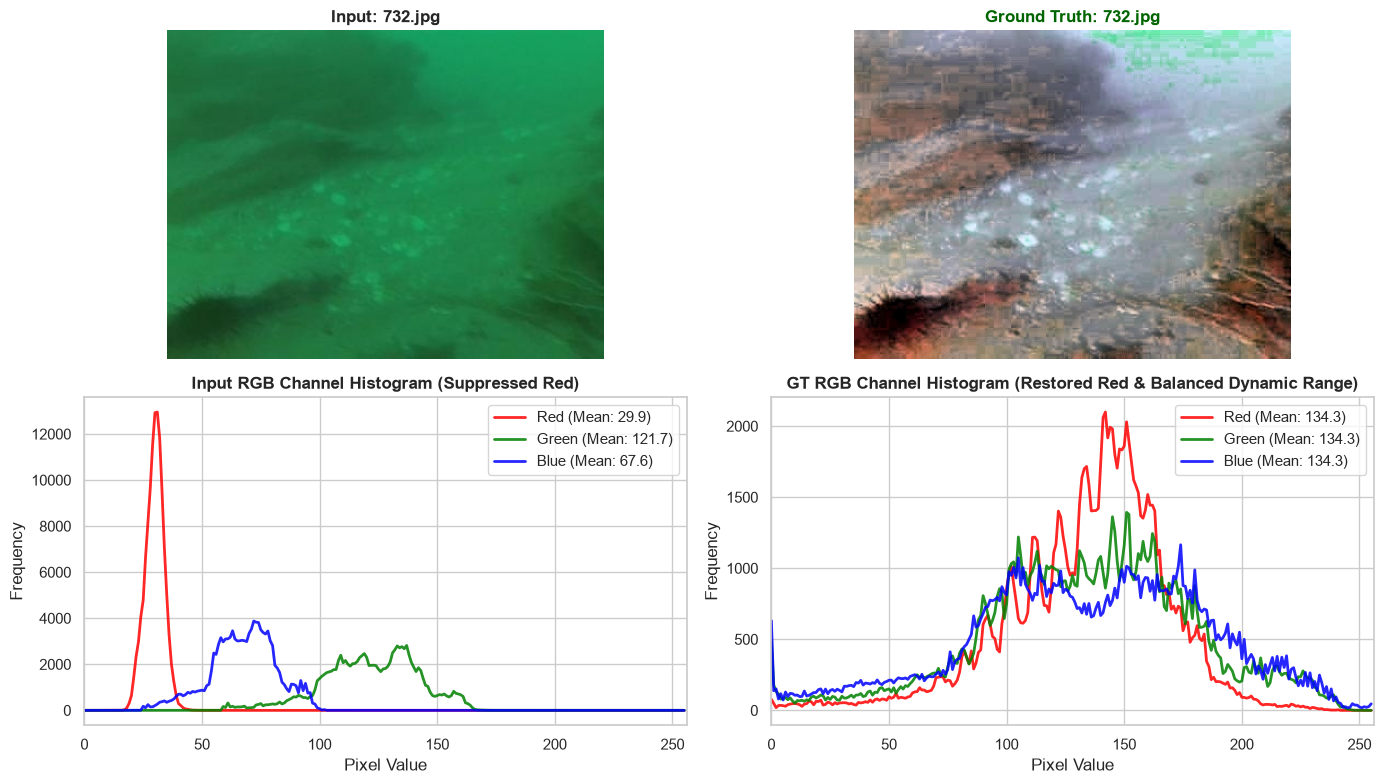

In [10]:
def plot_channel_histograms(image_name):
    img_in, img_gt, _ = load_image_pair(image_name)
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    
    # Visuals
    axes[0, 0].imshow(img_in)
    axes[0, 0].set_title(f"Input: {image_name}", fontweight="bold")
    axes[0, 0].axis("off")
    
    axes[0, 1].imshow(img_gt)
    axes[0, 1].set_title(f"Ground Truth: {image_name}", fontweight="bold", color="darkgreen")
    axes[0, 1].axis("off")
    
    colors = ('red', 'green', 'blue')
    
    # Input Histograms
    for i, col in enumerate(colors):
        hist_in = cv2.calcHist([img_in], [i], None, [256], [0, 256])
        axes[1, 0].plot(hist_in, color=col, alpha=0.85, linewidth=2, label=f"{col.title()} (Mean: {img_in[:,:,i].mean():.1f})")
    axes[1, 0].set_title("Input RGB Channel Histogram (Suppressed Red)", fontweight="bold")
    axes[1, 0].set_xlim([0, 256])
    axes[1, 0].set_xlabel("Pixel Value")
    axes[1, 0].set_ylabel("Frequency")
    axes[1, 0].legend()
    
    # GT Histograms
    for i, col in enumerate(colors):
        hist_gt = cv2.calcHist([img_gt], [i], None, [256], [0, 256])
        axes[1, 1].plot(hist_gt, color=col, alpha=0.85, linewidth=2, label=f"{col.title()} (Mean: {img_gt[:,:,i].mean():.1f})")
    axes[1, 1].set_title("GT RGB Channel Histogram (Restored Red & Balanced Dynamic Range)", fontweight="bold")
    axes[1, 1].set_xlim([0, 256])
    axes[1, 1].set_xlabel("Pixel Value")
    axes[1, 1].set_ylabel("Frequency")
    axes[1, 1].legend()
    
    plt.tight_layout()
    plt.show()

plot_channel_histograms(green_archetype)

Computing Channel Means: 100%|██████████| 300/300 [00:00<00:00, 484.91it/s]


,Raw Input,Enhanced GT
Red Channel,57.37,96.57
Green Channel,121.04,107.89
Blue Channel,107.85,107.53


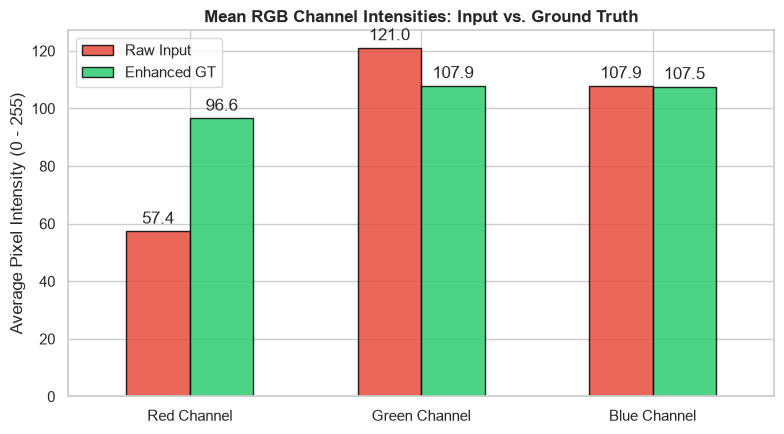

In [11]:
num_eval = min(300, len(df_meta))
eval_subset = df_meta.sample(n=num_eval, random_state=RANDOM_SEED)

ch_stats = []
for _, row in tqdm(eval_subset.iterrows(), total=num_eval, desc="Computing Channel Means"):
    img_in, img_gt, _ = load_image_pair(row["filename"])
    ch_stats.append({
        "in_r": img_in[:, :, 0].mean(),
        "in_g": img_in[:, :, 1].mean(),
        "in_b": img_in[:, :, 2].mean(),
        "gt_r": img_gt[:, :, 0].mean(),
        "gt_g": img_gt[:, :, 1].mean(),
        "gt_b": img_gt[:, :, 2].mean(),
    })

df_ch = pd.DataFrame(ch_stats)

means_df = pd.DataFrame({
    "Raw Input": [df_ch["in_r"].mean(), df_ch["in_g"].mean(), df_ch["in_b"].mean()],
    "Enhanced GT": [df_ch["gt_r"].mean(), df_ch["gt_g"].mean(), df_ch["gt_b"].mean()]
}, index=["Red Channel", "Green Channel", "Blue Channel"])

display(means_df.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
means_df.plot(kind="bar", ax=ax, color=["#e74c3c", "#2ecc71"], width=0.55, edgecolor="black", alpha=0.85)
ax.set_title("Mean RGB Channel Intensities: Input vs. Ground Truth", fontweight="bold")
ax.set_ylabel("Average Pixel Intensity (0 - 255)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", padding=3)
plt.tight_layout()
plt.show()

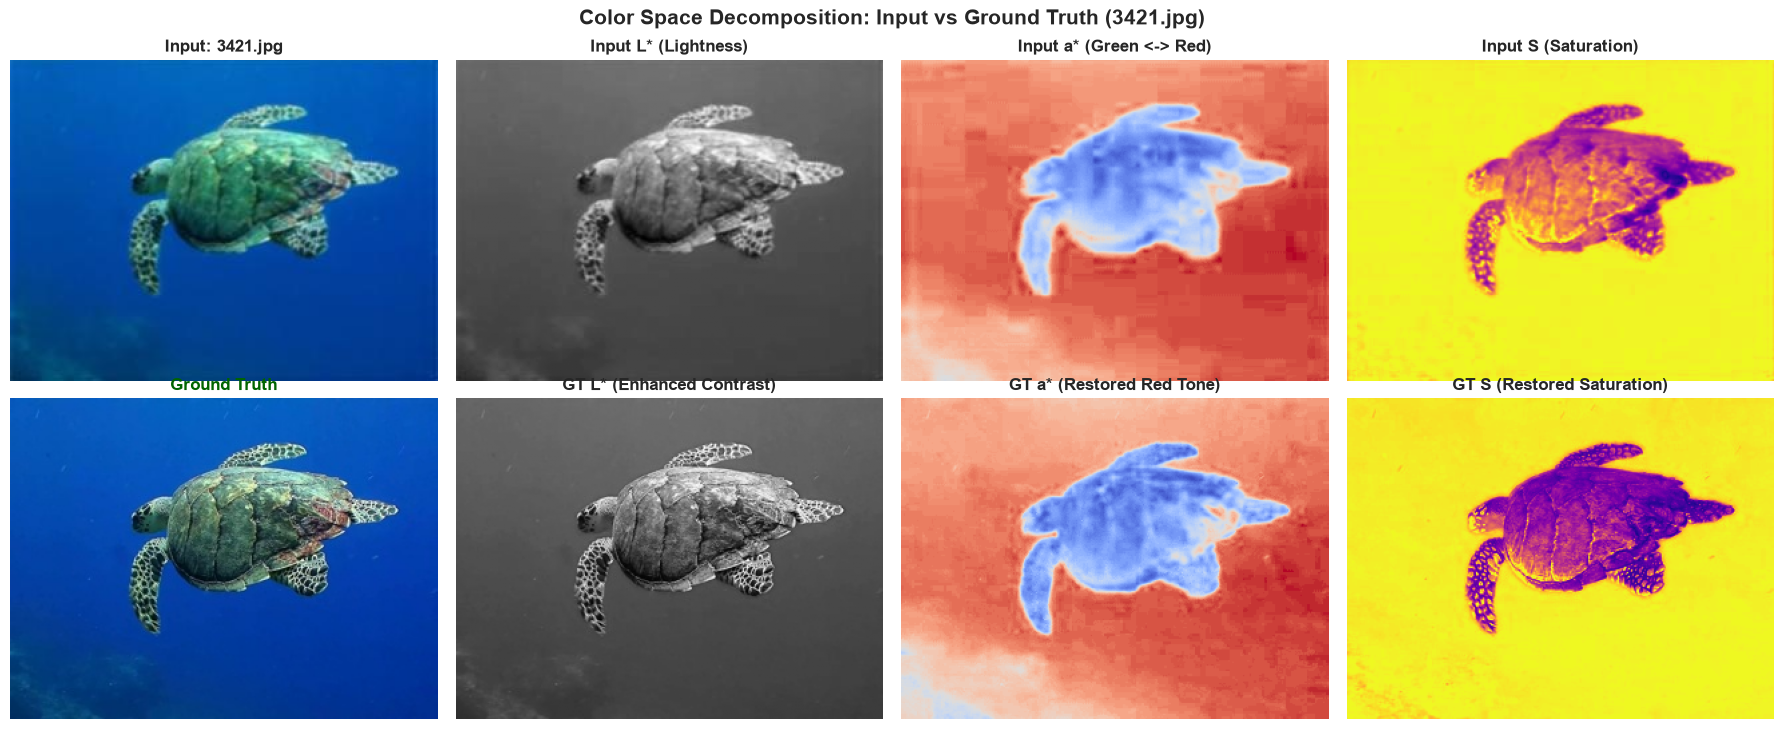

In [12]:
def plot_color_space_decomposition(image_name):
    img_in, img_gt, _ = load_image_pair(image_name)
    
    in_lab = cv2.cvtColor(img_in, cv2.COLOR_RGB2LAB)
    gt_lab = cv2.cvtColor(img_gt, cv2.COLOR_RGB2LAB)
    
    in_hsv = cv2.cvtColor(img_in, cv2.COLOR_RGB2HSV)
    gt_hsv = cv2.cvtColor(img_gt, cv2.COLOR_RGB2HSV)
    
    fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
    
    # Row 1: Input
    axes[0, 0].imshow(img_in)
    axes[0, 0].set_title(f"Input: {image_name}", fontweight="bold")
    axes[0, 0].axis("off")
    
    axes[0, 1].imshow(in_lab[:, :, 0], cmap="gray")
    axes[0, 1].set_title("Input L* (Lightness)", fontweight="bold")
    axes[0, 1].axis("off")
    
    axes[0, 2].imshow(in_lab[:, :, 1], cmap="coolwarm")
    axes[0, 2].set_title("Input a* (Green <-> Red)", fontweight="bold")
    axes[0, 2].axis("off")
    
    axes[0, 3].imshow(in_hsv[:, :, 1], cmap="plasma")
    axes[0, 3].set_title("Input S (Saturation)", fontweight="bold")
    axes[0, 3].axis("off")
    
    # Row 2: GT
    axes[1, 0].imshow(img_gt)
    axes[1, 0].set_title("Ground Truth", fontweight="bold", color="darkgreen")
    axes[1, 0].axis("off")
    
    axes[1, 1].imshow(gt_lab[:, :, 0], cmap="gray")
    axes[1, 1].set_title("GT L* (Enhanced Contrast)", fontweight="bold")
    axes[1, 1].axis("off")
    
    axes[1, 2].imshow(gt_lab[:, :, 1], cmap="coolwarm")
    axes[1, 2].set_title("GT a* (Restored Red Tone)", fontweight="bold")
    axes[1, 2].axis("off")
    
    axes[1, 3].imshow(gt_hsv[:, :, 1], cmap="plasma")
    axes[1, 3].set_title("GT S (Restored Saturation)", fontweight="bold")
    axes[1, 3].axis("off")
    
    plt.suptitle(f"Color Space Decomposition: Input vs Ground Truth ({image_name})", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()

plot_color_space_decomposition(blue_archetype)

Evaluating Sharpness & Contrast: 100%|██████████| 300/300 [00:01<00:00, 255.51it/s]


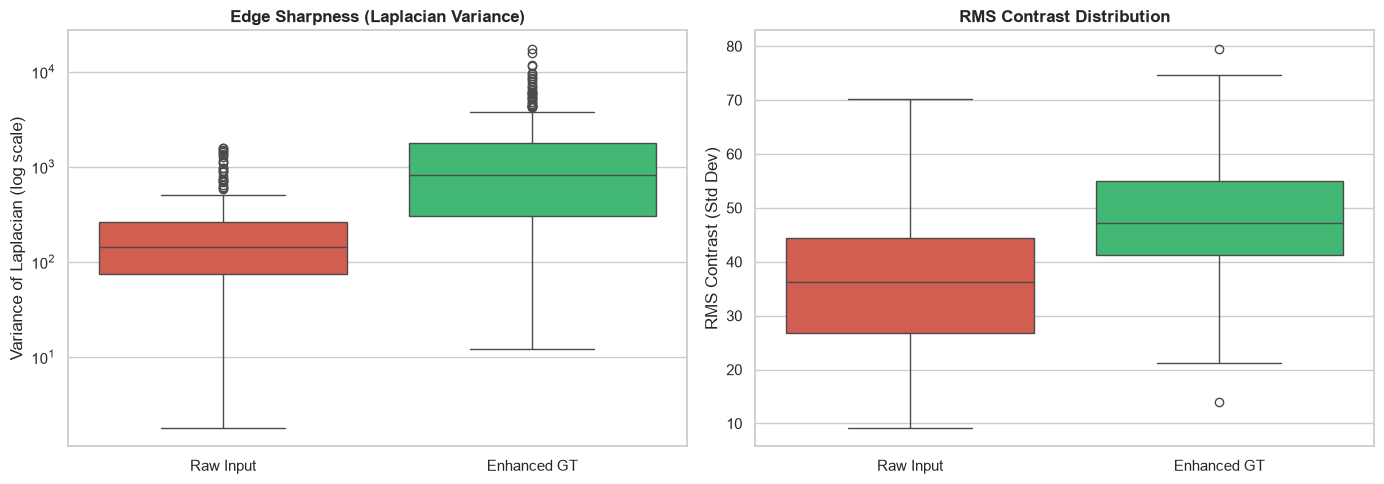

Median Sharpness Boost in GT: 5.10x
Median Contrast Boost in GT:  1.20x


In [13]:
def compute_sharpness_and_contrast(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float64)
    lap = cv2.Laplacian(gray, cv2.CV_64F)
    lap_var = lap.var()
    rms_contrast = gray.std()
    return lap_var, rms_contrast

quality_metrics = []
for _, row in tqdm(eval_subset.iterrows(), total=len(eval_subset), desc="Evaluating Sharpness & Contrast"):
    img_in, img_gt, _ = load_image_pair(row["filename"])
    in_sharpness, in_contrast = compute_sharpness_and_contrast(img_in)
    gt_sharpness, gt_contrast = compute_sharpness_and_contrast(img_gt)
    quality_metrics.append({
        "filename": row["filename"],
        "in_sharpness": in_sharpness,
        "gt_sharpness": gt_sharpness,
        "in_contrast": in_contrast,
        "gt_contrast": gt_contrast,
        "sharpness_gain": gt_sharpness / (in_sharpness + 1e-5),
        "contrast_gain": gt_contrast / (in_contrast + 1e-5)
    })

df_quality = pd.DataFrame(quality_metrics)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sharpness boxplot
df_sharp_box = pd.DataFrame({
    "Raw Input": df_quality["in_sharpness"],
    "Enhanced GT": df_quality["gt_sharpness"]
})
sns.boxplot(data=df_sharp_box, palette=["#e74c3c", "#2ecc71"], ax=axes[0])
axes[0].set_title("Edge Sharpness (Laplacian Variance)", fontweight="bold")
axes[0].set_yscale("log")
axes[0].set_ylabel("Variance of Laplacian (log scale)")

# Contrast boxplot
df_contrast_box = pd.DataFrame({
    "Raw Input": df_quality["in_contrast"],
    "Enhanced GT": df_quality["gt_contrast"]
})
sns.boxplot(data=df_contrast_box, palette=["#e74c3c", "#2ecc71"], ax=axes[1])
axes[1].set_title("RMS Contrast Distribution", fontweight="bold")
axes[1].set_ylabel("RMS Contrast (Std Dev)")

plt.tight_layout()
plt.show()

print(f"Median Sharpness Boost in GT: {df_quality['sharpness_gain'].median():.2f}x")
print(f"Median Contrast Boost in GT:  {df_quality['contrast_gain'].median():.2f}x")

Computing Baseline PSNR/SSIM: 100%|██████████| 100/100 [00:02<00:00, 37.49it/s]


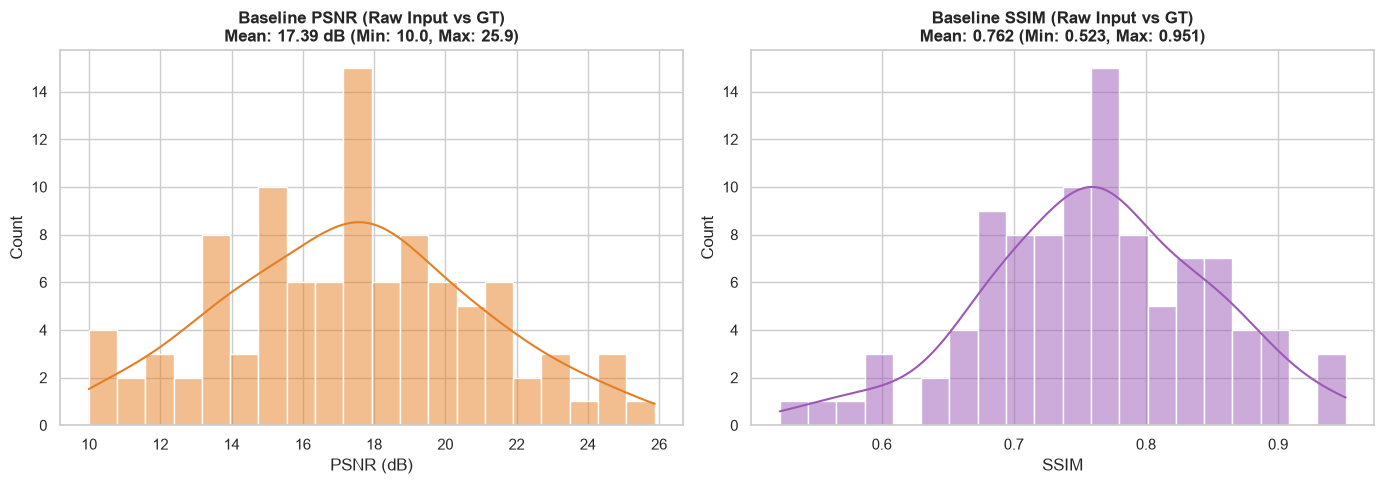

In [14]:
def calculate_psnr(img1, img2):
    mse = np.mean((img1.astype(np.float64) - img2.astype(np.float64)) ** 2)
    if mse == 0:
        return float('inf')
    return 20.0 * np.log10(255.0 / np.sqrt(mse))

def calculate_ssim(img1, img2):
    C1 = (0.01 * 255) ** 2
    C2 = (0.03 * 255) ** 2
    
    ssims = []
    for c in range(3):
        I1 = img1[:, :, c].astype(np.float64)
        I2 = img2[:, :, c].astype(np.float64)
        
        mu1 = cv2.GaussianBlur(I1, (11, 11), 1.5)
        mu2 = cv2.GaussianBlur(I2, (11, 11), 1.5)
        
        mu1_sq = mu1 ** 2
        mu2_sq = mu2 ** 2
        mu1_mu2 = mu1 * mu2
        
        sigma1_sq = cv2.GaussianBlur(I1 ** 2, (11, 11), 1.5) - mu1_sq
        sigma2_sq = cv2.GaussianBlur(I2 ** 2, (11, 11), 1.5) - mu2_sq
        sigma12 = cv2.GaussianBlur(I1 * I2, (11, 11), 1.5) - mu1_mu2
        
        ssim_map = ((2 * mu1_mu2 + C1) * (2 * sigma12 + C2)) / ((mu1_sq + mu2_sq + C1) * (sigma1_sq + sigma2_sq + C2))
        ssims.append(ssim_map.mean())
    return float(np.mean(ssims))

bench_records = []
for _, row in tqdm(eval_subset.head(100).iterrows(), total=100, desc="Computing Baseline PSNR/SSIM"):
    img_in, img_gt, _ = load_image_pair(row["filename"])
    bench_records.append({
        "filename": row["filename"],
        "psnr": calculate_psnr(img_in, img_gt),
        "ssim": calculate_ssim(img_in, img_gt)
    })

df_bench = pd.DataFrame(bench_records)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_bench["psnr"], bins=20, kde=True, color="#e67e22", ax=axes[0])
axes[0].set_title(f"Baseline PSNR (Raw Input vs GT)\nMean: {df_bench['psnr'].mean():.2f} dB (Min: {df_bench['psnr'].min():.1f}, Max: {df_bench['psnr'].max():.1f})", fontweight="bold")
axes[0].set_xlabel("PSNR (dB)")

sns.histplot(df_bench["ssim"], bins=20, kde=True, color="#9b59b6", ax=axes[1])
axes[1].set_title(f"Baseline SSIM (Raw Input vs GT)\nMean: {df_bench['ssim'].mean():.3f} (Min: {df_bench['ssim'].min():.3f}, Max: {df_bench['ssim'].max():.3f})", fontweight="bold")
axes[1].set_xlabel("SSIM")

plt.tight_layout()
plt.show()

In [15]:
def create_dataset_splits(df, train_ratio=0.8, val_ratio=0.1, seed=42):
    shuffled_df = df.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    n = len(shuffled_df)
    n_train = int(n * train_ratio)
    n_val = int(n * val_ratio)
    
    shuffled_df["split"] = "train"
    shuffled_df.loc[n_train:n_train + n_val, "split"] = "val"
    shuffled_df.loc[n_train + n_val:, "split"] = "test"
    return shuffled_df

df_splits = create_dataset_splits(df_meta, train_ratio=0.8, val_ratio=0.1, seed=RANDOM_SEED)

print("Split Distribution:")
print(df_splits["split"].value_counts())

# Export to dataset folder and project root
split_path = DATASET_DIR / "lsui_splits.csv"
df_splits[["id", "filename", "width", "height", "aspect_ratio", "megapixels", "split"]].to_csv(split_path, index=False)
print(f"\n[SUCCESS] Split definitions saved to: {split_path}")

Split Distribution:
split
train    3423
test      429
val       427
Name: count, dtype: int64

[SUCCESS] Split definitions saved to: E:\sem5_project\dataset\LSUI\lsui_splits.csv
